<h2>IBM Customer Churn Problem and EDA</h2>

<img src="https://images.ctfassets.net/o7xu9whrs0u9/2wcsVnQR5JSp4P4BXhlWLb/55b8a2de6d04d0b0820743aa3a75d6b7/IBM-logo.png" width="100px"/><br/>

IBM (International Business Machines Corporation) is a global technology company specialising in enterprise computing, software, cloud technologies, artificial intelligence, data and analytics, and consulting services. As part of its analytics resources, IBM provides the <b>Telco Customer Churn</b> sample dataset for demonstrating customer analytics and churn modelling.

The dataset represents a <b>fictional telecommunications company</b> providing home phone and Internet services to 7,043 customers in California (<a href="https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113">link</a>). It contains customer demographic, account, service, billing and behavioural information, together with indicators showing whether customers remained with or left the company. The dataset can be used to investigate the factors associated with customer attrition and to develop machine-learning models for predicting customer churn and supporting data-driven retention strategies. 

<h2>Data and Data Exploration</h2>

In [1]:
import pandas as pd

df = pd.read_csv('../data/input/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

<h2>I. Featuring Engineering and EDA</h2>

<h4>I.1. Important Feature Selection</h4>

In [3]:
dataset_df = df.drop(columns=['customerID'])
dataset_df['MonthlyCharges'] = pd.to_numeric(dataset_df['MonthlyCharges'], errors="coerce")
dataset_df['TotalCharges'] = pd.to_numeric(dataset_df['TotalCharges'], errors="coerce")

#Binarize obvious variables
columns = ['Partner', 'Dependents', 'PhoneService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']
for column in columns:
    dataset_df[column] = dataset_df[column].apply(lambda x: 1 if "yes" in x.lower() else 0 if "no" in x.lower() else np.nan())
    dataset_df[column] = dataset_df[column].astype(int)
dataset_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,1,0,1,0,No phone service,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,No
1,Male,0,0,0,34,1,No,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,No
2,Male,0,0,0,2,1,No,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,Yes
3,Male,0,0,0,45,0,No phone service,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,0,0,2,1,No,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,Yes


<h4>I.2. Missing values and Data Imputation</h4>

In [4]:
ds_series = dataset_df.isnull().sum()
ds_summary_df = pd.DataFrame({
    "attribute":dataset_df.columns,
    "missing count":ds_series.values,
    "missing perc(%)": ds_series.values*100/dataset_df.shape[0]
})
ds_summary_df

,attribute,missing count,missing perc(%)
0,gender,0,0.000000
1,SeniorCitizen,0,0.000000
2,Partner,0,0.000000
3,Dependents,0,0.000000
4,tenure,0,0.000000
5,PhoneService,0,0.000000
6,MultipleLines,0,0.000000
7,InternetService,0,0.000000
8,OnlineSecurity,0,0.000000
9,OnlineBackup,0,0.000000


In [5]:
dataset_df.dropna(inplace=True)#Nan data points

<h3>I.3. Correlation analysis to Target</h3>

<Figure size 640x480 with 0 Axes>

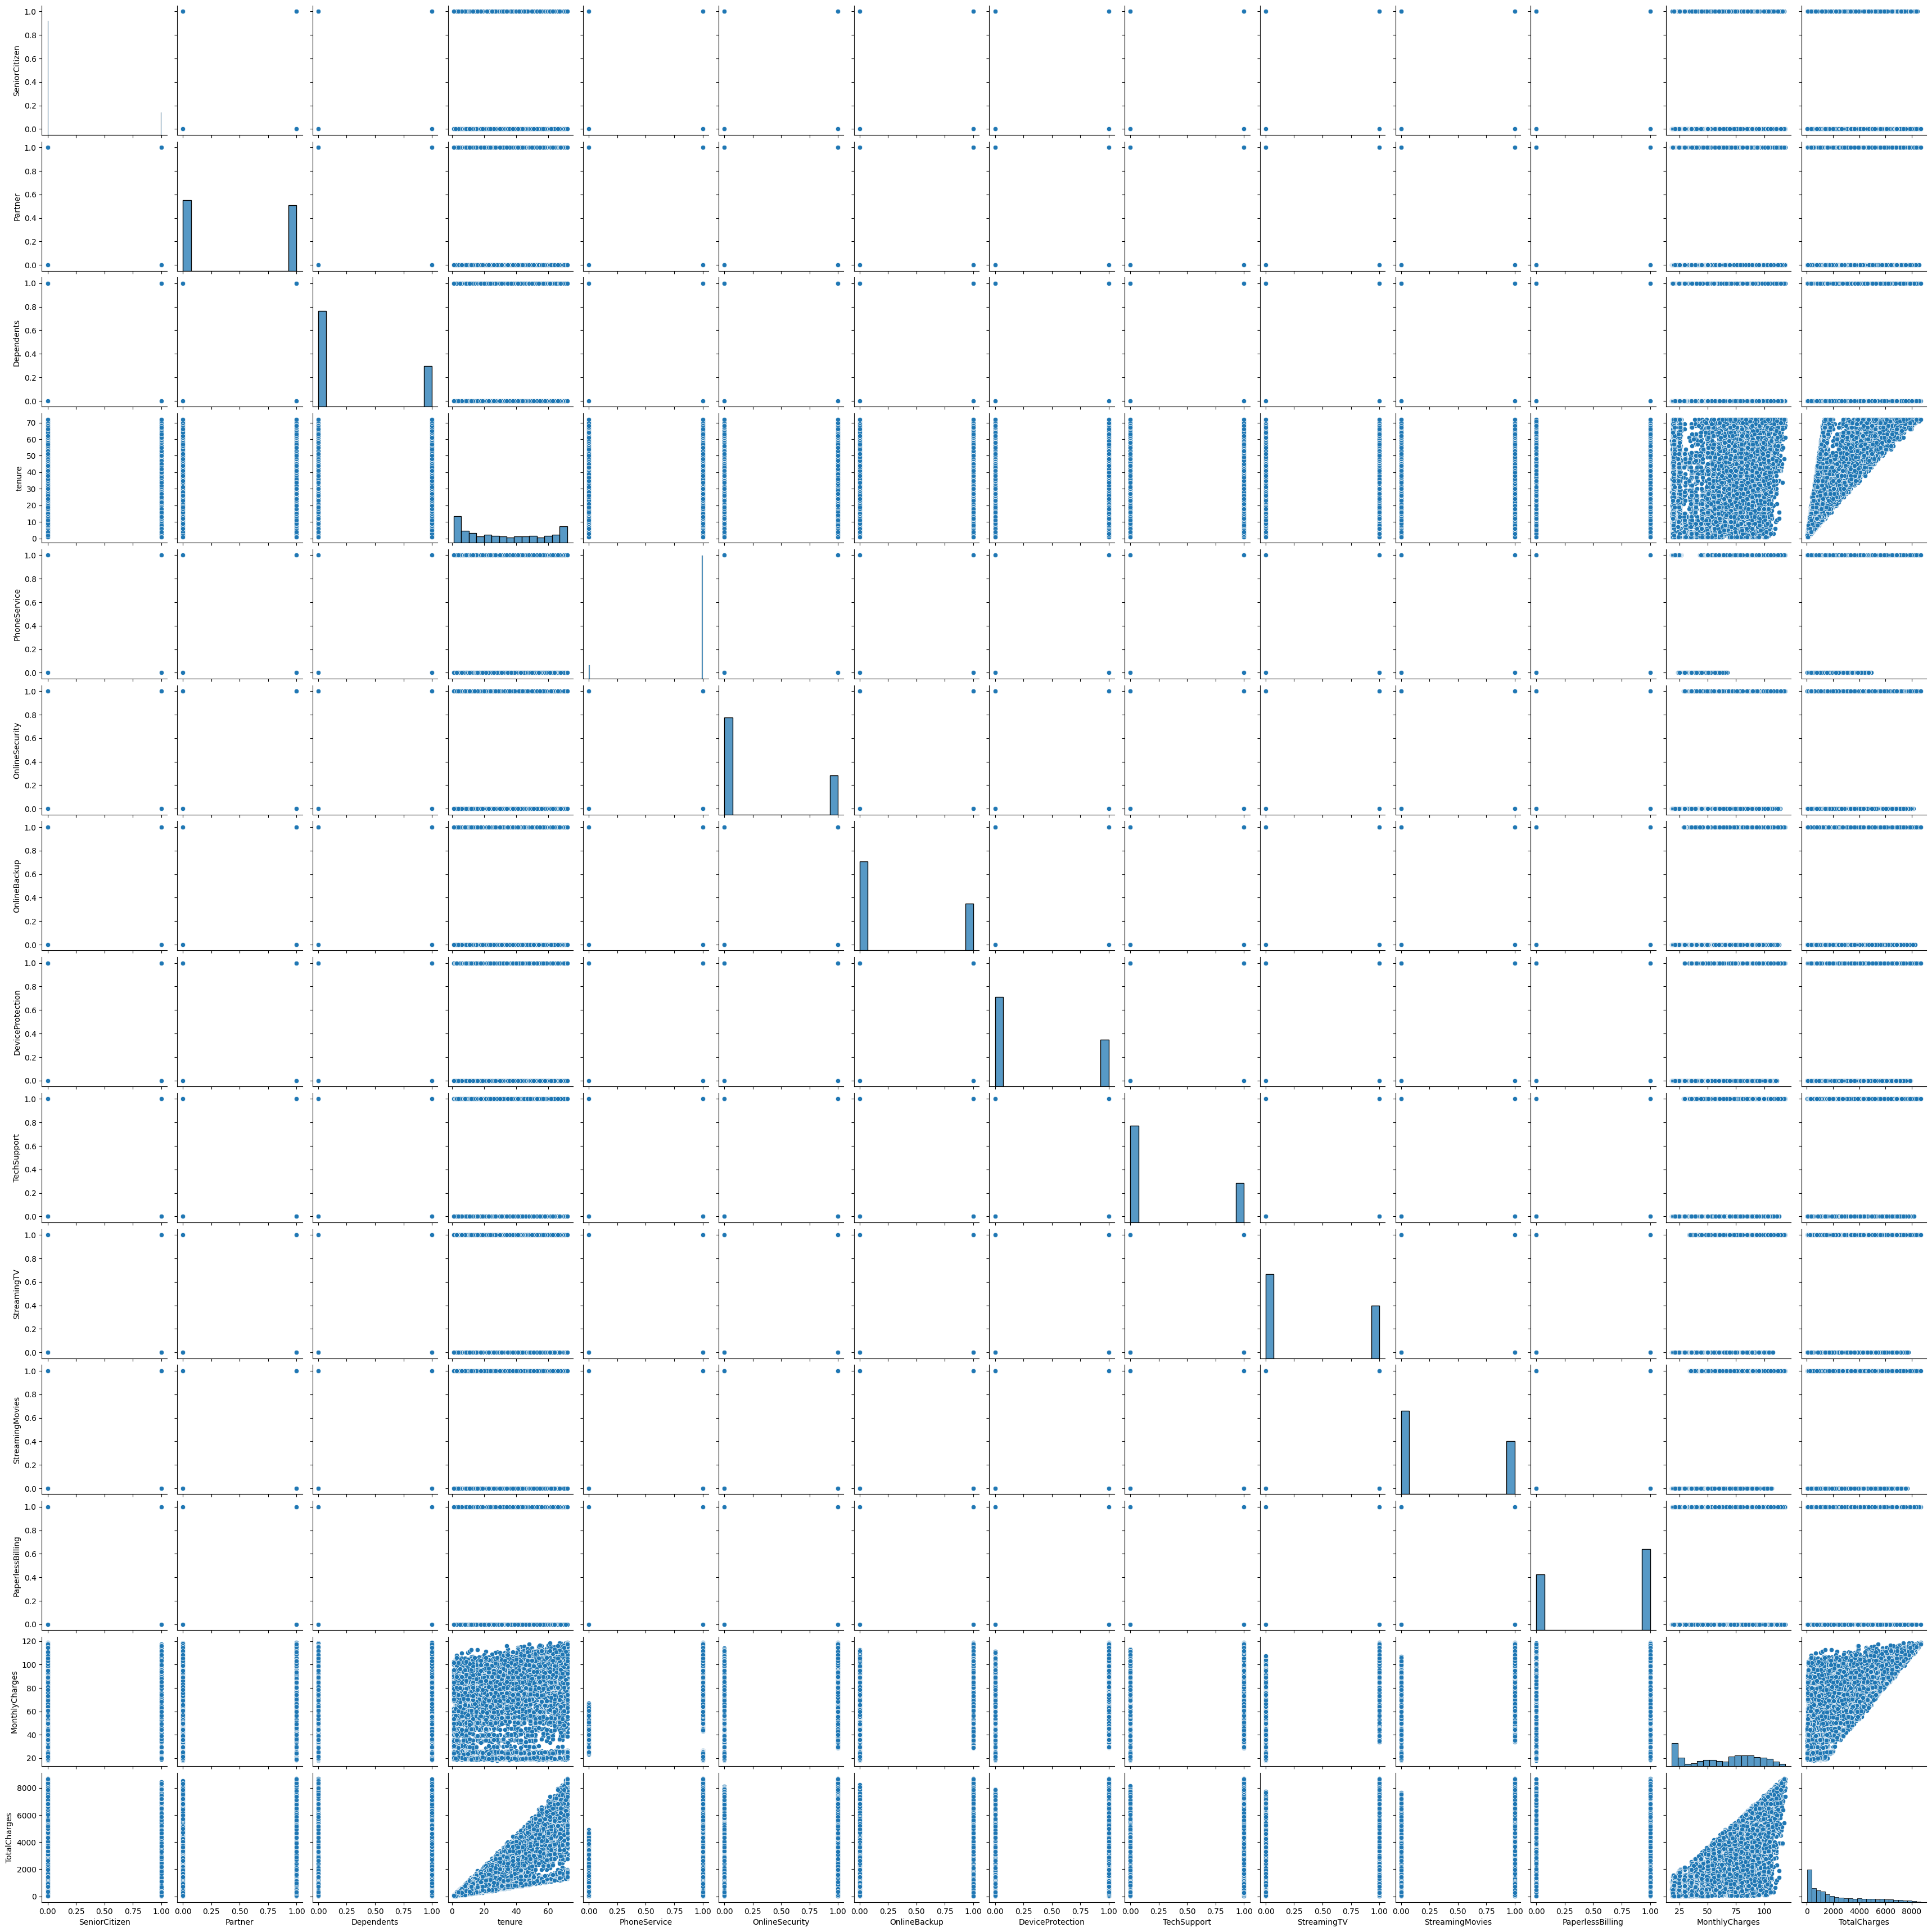

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure()
sns.pairplot(dataset_df)
plt.show()


<h4>I.4 Class Imbalance</h4>

<Axes: xlabel='Churn', ylabel='count'>

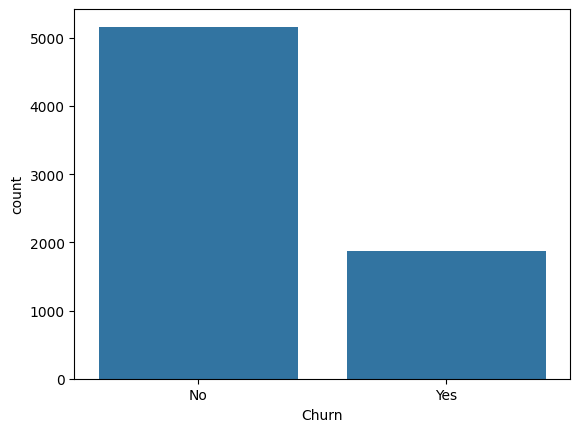

In [7]:
sns.countplot(data=dataset_df,x='Churn')

<h3>II. Data Split </h3>

In [8]:
from sklearn.model_selection import train_test_split
X_d = dataset_df.drop(columns=['Churn'])
X = pd.get_dummies(X_d,dtype=int)
y = dataset_df[['Churn']]



X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, shuffle=True, random_state=1234)

In [9]:
X_train.to_csv('../data/input/X_train.csv',index=False)
y_train.to_csv('../data/input/y_train.csv',index=False)
X_test.to_csv('../data/input/X_test.csv',index=False)
y_test.to_csv('../data/input/y_test.csv',index=False)
#Data export